# Feature Engineering and Model Development

## 1. Objective

To prepare the Heart Disease dataset for machine learning by applying
appropriate preprocessing, and to train and evaluate Logistic Regression
and Random Forest classifiers using cross-validation and relevant
classification metrics.

## 2. Prepare final ML features (scaling, encoding).

### 2.1 Import Libraries , Load Dataset and convert target to binary

In [ ]:
#2.1.1 Import Libraries

from pathlib import Path

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

##2.1.2 Load Dataset
DATA_PATH = Path("../data/raw/heart_disease.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df.head())


##2.1.3 convert the original UCI target to binary
df["target"] = (df["target"] > 0).astype(int)
print(df["target"].value_counts())

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


target
0    164
1    139
Name: count, dtype: int64


### 2.2 Define Features&Target, Split Train/Test

In [2]:
#2.2.1 Define Features and Target
X = df.drop("target", axis=1)
y = df["target"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)


#2.2.2 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Features shape: (303, 13)
Target shape: (303,)
Training samples: 242
Testing samples: 61

Training class distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
target
0    33
1    28
Name: count, dtype: int64


### 2.3 Define Numerical and Categorical Features

The features are divided into numerical and categorical groups so that
appropriate preprocessing can be applied. Numerical features will be
imputed and standardized, while categorical features will be imputed
and one-hot encoded.

In [3]:
# Numerical features
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Categorical features
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


### 2.4 Preprocessing Pipeline

Missing values are handled within the preprocessing pipeline to avoid
data leakage. Numerical features are imputed using the median and
standardized using StandardScaler. Categorical features are imputed
using the most frequent value and transformed using one-hot encoding.

In [4]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

## 3. Build and train two classification models

### 3.1 Logistic Regression

Logistic Regression is used as a linear classification model and
provides a suitable baseline for the binary heart disease prediction
task.

In [5]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

#Now train it:
logistic_pipeline.fit(X_train, y_train)
print("Logistic Regression training completed.")

Logistic Regression training completed.


### 3.2 Random Forest

Random Forest is used as a non-linear ensemble classification model
to provide a comparison with Logistic Regression.

In [6]:
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42
    ))
])

#Now train it:
random_forest_pipeline.fit(X_train, y_train)
print("Random Forest training completed.")

Random Forest training completed.


## 4. Evaluate using cross validation and relevant metrics
Stratified K-Fold cross-validation is used to evaluate the performance
of both classification models across multiple training and validation
splits while preserving the class distribution in each fold.

The models are evaluated using accuracy, precision, recall, and
ROC-AUC as required for the classification task.

In [ ]:
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


#Evaluation Metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

### 4.1 Logistic Regression Cross-Validation

In [8]:
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("Logistic Regression Cross-Validation Results")

print(
    "Accuracy:",
    logistic_cv["test_accuracy"].mean()
)

print(
    "Precision:",
    logistic_cv["test_precision"].mean()
)

print(
    "Recall:",
    logistic_cv["test_recall"].mean()
)

print(
    "ROC-AUC:",
    logistic_cv["test_roc_auc"].mean()
)

Logistic Regression Cross-Validation Results
Accuracy: 0.8471088435374149
Precision: 0.8767529146045769
Recall: 0.783399209486166
ROC-AUC: 0.9024931590148981


### 4.2 Random Forest Cross-Validation

In [9]:
random_forest_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("Random Forest Cross-Validation Results")

print(
    "Accuracy:",
    random_forest_cv["test_accuracy"].mean()
)

print(
    "Precision:",
    random_forest_cv["test_precision"].mean()
)

print(
    "Recall:",
    random_forest_cv["test_recall"].mean()
)

print(
    "ROC-AUC:",
    random_forest_cv["test_roc_auc"].mean()
)

Random Forest Cross-Validation Results
Accuracy: 0.8181122448979592
Precision: 0.8172527472527472
Recall: 0.7826086956521738
ROC-AUC: 0.8972036417688593


### 4.3 Create a Comparison Table

In [10]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_cv["test_accuracy"].mean(),
        random_forest_cv["test_accuracy"].mean()
    ],
    "Precision": [
        logistic_cv["test_precision"].mean(),
        random_forest_cv["test_precision"].mean()
    ],
    "Recall": [
        logistic_cv["test_recall"].mean(),
        random_forest_cv["test_recall"].mean()
    ],
    "ROC-AUC": [
        logistic_cv["test_roc_auc"].mean(),
        random_forest_cv["test_roc_auc"].mean()
    ]
})

cv_results.round(4)

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.8471,0.8768,0.7834,0.9025
1,Random Forest,0.8181,0.8173,0.7826,0.8972


Logistic Regression currently performs better on all four metrics, while recall is almost identical. We can therefore say it is the stronger baseline model before tuning.

## 5. Hyperparameter Tuning

Hyperparameter tuning is performed to identify suitable model
configurations for Logistic Regression and Random Forest.

GridSearchCV with stratified 5-fold cross-validation is used to
systematically evaluate the selected hyperparameter combinations.
ROC-AUC is used as the optimization metric.

### 5.1 Logistic Regression tuning

In [ ]:
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

#run GridSearchCV:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("\nBest Logistic Regression CV ROC-AUC:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'model__C': 1}

Best Logistic Regression CV ROC-AUC:
0.9024931590148981


### 5.2 Random Forest tuning

In [12]:
random_forest_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

#run GridSearchCV:
random_forest_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

random_forest_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(random_forest_grid.best_params_)

print("\nBest Random Forest CV ROC-AUC:")
print(random_forest_grid.best_score_)

Best Random Forest parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best Random Forest CV ROC-AUC:
0.8983694244563811


### 5.3 Compare the tuned models

In [13]:
tuning_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Best CV ROC-AUC": [
        logistic_grid.best_score_,
        random_forest_grid.best_score_
    ],
    "Best Parameters": [
        logistic_grid.best_params_,
        random_forest_grid.best_params_
    ]
})

tuning_results

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.902493,{'model__C': 1}
1,Random Forest,0.898369,"{'model__max_depth': None, 'model__min_samples..."


## 6. Final Test-Set Evaluation

The best-tuned Logistic Regression and Random Forest models are
evaluated on the held-out test set. The test set was not used during
model training or hyperparameter tuning.

Performance is evaluated using accuracy, precision, recall, and
ROC-AUC.

In [14]:
# Get the best tuned models
best_logistic_model = logistic_grid.best_estimator_
best_random_forest_model = random_forest_grid.best_estimator_


# Generate predictions:
#Logistic Regression predictions
lr_predictions = best_logistic_model.predict(X_test)
lr_probabilities = best_logistic_model.predict_proba(X_test)[:, 1]

#Random Forest predictions
rf_predictions = best_random_forest_model.predict(X_test)
rf_probabilities = best_random_forest_model.predict_proba(X_test)[:, 1]


# Calculate evaluation metrics:
# Logistic Regression
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_roc_auc = roc_auc_score(y_test, lr_probabilities)

# Random Forest
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

# Create final comparison table

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall
    ],
    "ROC-AUC": [
        lr_roc_auc,
        rf_roc_auc
    ]
})

final_results.round(4)


,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.9665
1,Random Forest,0.8852,0.8387,0.9286,0.9545


In [15]:
print("Final Test-Set Results")
print("=" * 60)

for _, row in final_results.iterrows():
    print(f"\n{row['Model']}")
    print(f"Accuracy : {row['Accuracy']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"Recall   : {row['Recall']:.4f}")
    print(f"ROC-AUC  : {row['ROC-AUC']:.4f}")

Final Test-Set Results

Logistic Regression
Accuracy : 0.8852
Precision: 0.8387
Recall   : 0.9286
ROC-AUC  : 0.9665

Random Forest
Accuracy : 0.8852
Precision: 0.8387
Recall   : 0.9286
ROC-AUC  : 0.9545


## 7. Final Model Comparison

The tuned Logistic Regression and Random Forest models were evaluated
on the held-out test set using accuracy, precision, recall, and ROC-AUC.

Both models achieved the same accuracy, precision, and recall. However,
Logistic Regression achieved a higher ROC-AUC than Random Forest.
Therefore, Logistic Regression is selected as the final model.

## 8. Save Final Model

The tuned Logistic Regression model is selected as the final model and
saved for use in the subsequent inference/API stage.

In [ ]:
from pathlib import Path

import joblib

MODEL_PATH = Path("../models")

MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_logistic_model,
    MODEL_PATH / "heart_disease_logistic_regression.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


## 9. Experiment Tracking — MLflow

In [ ]:
import os

import mlflow
import mlflow.sklearn

os.environ["GIT_PYTHON_REFRESH"] = "quiet"

mlflow.set_experiment("Heart Disease Classification")


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


<Experiment: artifact_location='file:///d:/pavan_Mtech/s3/MLops/mlops-heart-disease/notebooks/mlruns/1', creation_time=1792432795351, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792432795351, lifecycle_stage='active', name='Heart Disease Classification', tags={}, trace_location=None, workspace='default'>

### 9.1 Track Logistic Regression baseline

In [18]:
with mlflow.start_run(run_name="Logistic Regression Baseline"):

    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("cv_accuracy", logistic_cv["test_accuracy"].mean())
    mlflow.log_metric("cv_precision", logistic_cv["test_precision"].mean())
    mlflow.log_metric("cv_recall", logistic_cv["test_recall"].mean())
    mlflow.log_metric("cv_roc_auc", logistic_cv["test_roc_auc"].mean())

    mlflow.sklearn.log_model(
    sk_model=logistic_pipeline,
    name="model",
    skops_trusted_types=["numpy.dtype"],
    )
print("Logistic Regression baseline logged.")

Logistic Regression baseline logged.


### 9.2 Track Random Forest baseline

In [19]:
with mlflow.start_run(run_name="Random Forest Baseline"):

    mlflow.log_param("model", "Random Forest")
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("cv_accuracy", random_forest_cv["test_accuracy"].mean())
    mlflow.log_metric("cv_precision", random_forest_cv["test_precision"].mean())
    mlflow.log_metric("cv_recall", random_forest_cv["test_recall"].mean())
    mlflow.log_metric("cv_roc_auc", random_forest_cv["test_roc_auc"].mean())

    mlflow.sklearn.log_model(
        sk_model=random_forest_pipeline,
        name="model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
print("Random Forest baseline logged.")

2026/10/20 13:37:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest baseline logged.


### 9.3 Track tuned Logistic Regression

In [20]:
with mlflow.start_run(run_name="Logistic Regression Tuned"):

    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param(
        "C",
        logistic_grid.best_params_["model__C"]
    )

    mlflow.log_metric(
        "cv_roc_auc",
        logistic_grid.best_score_
    )

    mlflow.log_metric("test_accuracy", lr_accuracy)
    mlflow.log_metric("test_precision", lr_precision)
    mlflow.log_metric("test_recall", lr_recall)
    mlflow.log_metric("test_roc_auc", lr_roc_auc)

    mlflow.sklearn.log_model(
        sk_model=best_logistic_model,
        name="model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
print("Tuned Logistic Regression logged.")

2026/10/20 13:37:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Tuned Logistic Regression logged.


### 9.4 Track tuned Random Forest

In [21]:
with mlflow.start_run(run_name="Random Forest Tuned"):

    mlflow.log_param("model", "Random Forest")

    mlflow.log_params({
        "n_estimators":
            random_forest_grid.best_params_["model__n_estimators"],
        "max_depth":
            random_forest_grid.best_params_["model__max_depth"],
        "min_samples_split":
            random_forest_grid.best_params_["model__min_samples_split"]
    })

    mlflow.log_metric(
        "cv_roc_auc",
        random_forest_grid.best_score_
    )

    mlflow.log_metric("test_accuracy", rf_accuracy)
    mlflow.log_metric("test_precision", rf_precision)
    mlflow.log_metric("test_recall", rf_recall)
    mlflow.log_metric("test_roc_auc", rf_roc_auc)

    mlflow.sklearn.log_model(
        sk_model=best_random_forest_model,
        name="model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )

print("Tuned Random Forest logged.")

2026/10/20 13:37:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Tuned Random Forest logged.


## 10. Log the model plots as artifacts

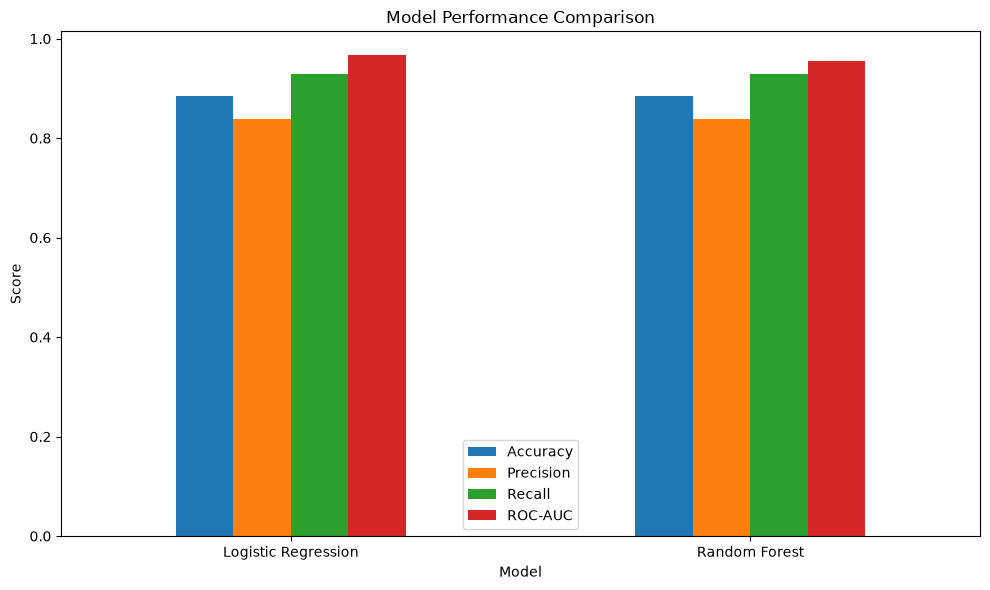

Plot logged to MLflow.


In [22]:
#save final comparison plot:
import matplotlib.pyplot as plt

final_results_plot = final_results.set_index("Model")

ax = final_results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()

plot_path = "../models/model_performance_comparison.png"
plt.savefig(plot_path)
plt.show()

#log it
with mlflow.start_run(run_name="Final Model Artifacts"):

    mlflow.log_artifact(
        plot_path,
        artifact_path="plots"
    )

print("Plot logged to MLflow.")


# Log all saved EDA PNG files
screenshots_dir = Path("../screenshots")
for plot_file in screenshots_dir.glob("*.png"):
    mlflow.log_artifact(str(plot_file), artifact_path="EDA_plots")